# Model fitting 2: Only SSC and extended radio jet, MCMC without minimizer step

In [1]:
#import warnings
#warnings.filterwarnings('ignore')

import matplotlib.pylab as plt
import jetset
from jetset.test_data_helper import  test_SEDs
from jetset.data_loader import ObsData,Data
from jetset.plot_sedfit import PlotSED
from jetset.test_data_helper import  test_SEDs

In [2]:
print(jetset.__version__)

1.4.0rc3


In [3]:
test_SEDs

['/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/test_data/SEDs_data/SED_3C345.ecsv',
 '/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/test_data/SEDs_data/SED_MW_Mrk421_EBL_DEABS.ecsv',
 '/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/test_data/SEDs_data/SED_MW_Mrk501_EBL_ABS.ecsv',
 '/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/test_data/SEDs_data/SED_MW_Mrk501_EBL_DEABS.ecsv']

## Loading data



In [4]:
print(test_SEDs[1])
data=Data.from_file(test_SEDs[1])


/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/test_data/SEDs_data/SED_MW_Mrk421_EBL_DEABS.ecsv



***  binning data in [2276544600.0,9.69946733e+26] Hz  *** 
---> N bins= 88
---> bin_width= 0.2



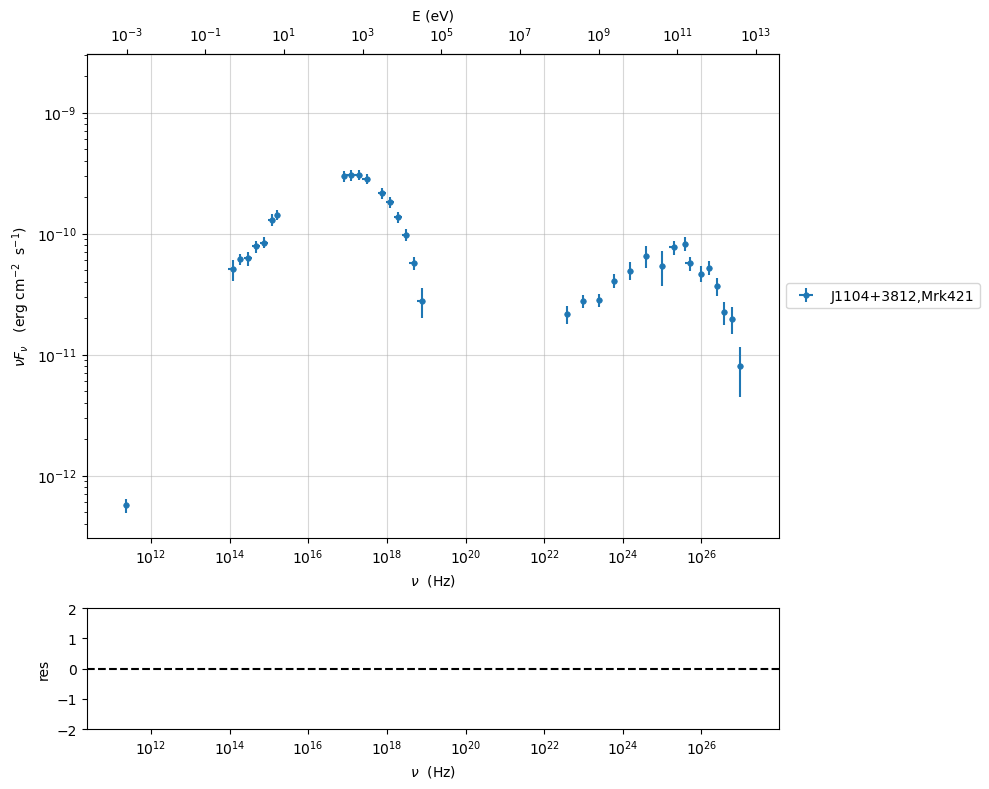

In [5]:
%matplotlib inline
sed_data=ObsData(data_table=data)
sed_data.group_data(bin_width=0.2)

sed_data.add_systematics(0.1,[10.**6,10.**29])
p=sed_data.plot_sed()
#p.setlim(y_min=1E-15,x_min=1E7,x_max=1E29)

In [6]:
sed_data.save('Mrk_401.pkl')

## phenomenological model constraining

### spectral indices


*** evaluating spectral indices for data ***



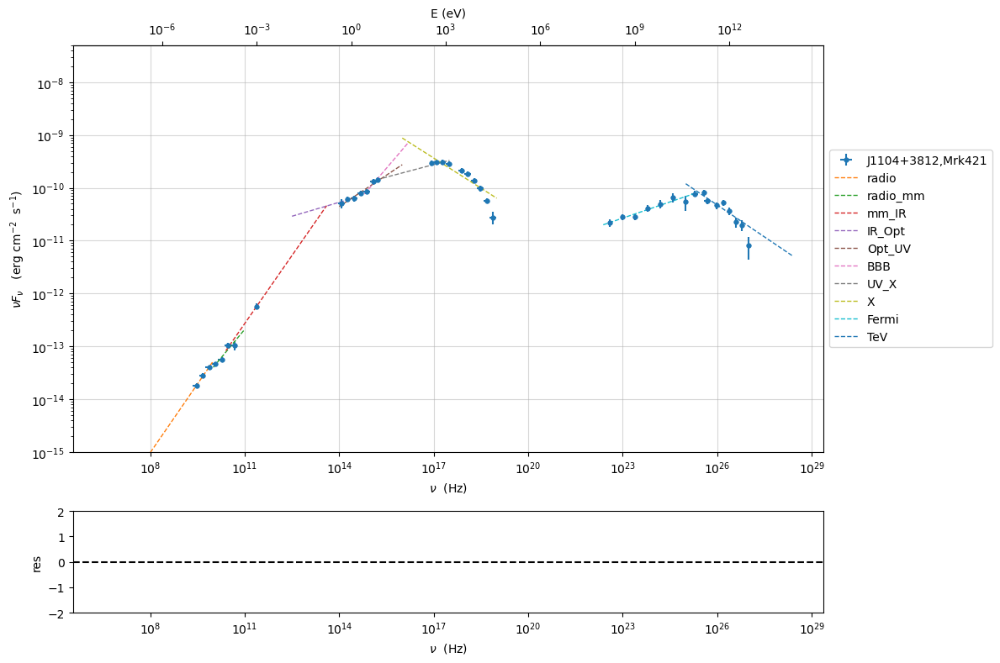

In [7]:
from jetset.sed_shaper import  SEDShape
my_shape=SEDShape(sed_data)
my_shape.eval_indices(minimizer='lsb',silent=True)
p=my_shape.plot_indices()
p.setlim(y_min=1E-15,y_max=5E-8)

### sed shaper

In [8]:
mm,best_fit=my_shape.sync_fit(check_host_gal_template=False,
                  Ep_start=None,
                  minimizer='lsb',
                  silent=True,
                  fit_range=[10.,21.])


*** Log-Polynomial fitting of the synchrotron component ***
---> first blind fit run,  fit range: [10.0, 21.0]
---> class:  HSP





model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.525958e-01,-1.525958e-01,6.482036e-03,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-9.962792e-03,-9.962792e-03,9.541920e-04,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,1.674375e+01,1.674375e+01,2.624853e-02,--,1.669194e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-9.498549e+00,-9.498549e+00,1.847153e-02,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> sync       nu_p=+1.674375e+01 (err=+2.624853e-02)  nuFnu_p=-9.498549e+00 (err=+1.847153e-02) curv.=-1.525958e-01 (err=+6.482036e-03)




*** Log-Polynomial fitting of the IC component ***
---> fit range: [23.0, 29.0]
---> LogCubic fit




model name,name,val,bestfit val,err +,err -,start val,fit range min,fit range max,frozen
LogCubic,b,-1.961746e-01,-1.961746e-01,2.682131e-02,--,-1.000000e+00,-1.000000e+01,0.000000e+00,False
LogCubic,c,-4.013229e-02,-4.013229e-02,2.124386e-02,--,-1.000000e+00,-1.000000e+01,1.000000e+01,False
LogCubic,Ep,2.521741e+01,2.521741e+01,1.206301e-01,--,2.529193e+01,0.000000e+00,3.000000e+01,False
LogCubic,Sp,-1.012689e+01,-1.012689e+01,2.978342e-02,--,-1.000000e+01,-3.000000e+01,0.000000e+00,False


---> IC         nu_p=+2.521741e+01 (err=+1.206301e-01)  nuFnu_p=-1.012689e+01 (err=+2.978342e-02) curv.=-1.961746e-01 (err=+2.682131e-02)



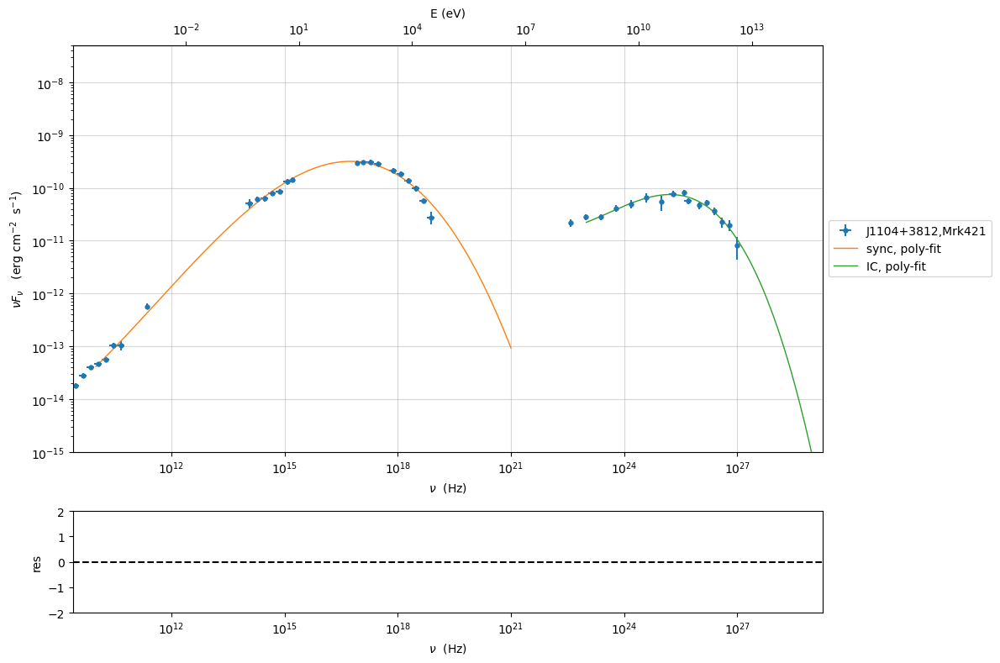

In [9]:
my_shape.IC_fit(fit_range=[23.,29.],minimizer='minuit',silent=True)
p=my_shape.plot_shape_fit()
p.setlim(y_min=1E-15,y_max=5E-8)

### Model constraining

In this step we are not fitting the model, we are just obtaining the phenomenological `pre_fit` model, that will be fitted in using minuit ore least-square bound, as shown below

In [10]:
from jetset.obs_constrain import ObsConstrain
from jetset.model_manager import  FitModel
sed_obspar=ObsConstrain(beaming=25,
                        B_range=[0.001,0.1],
                        distr_e='lppl',
                        t_var_sec=3*86400,
                        nu_cut_IR=1E12,
                        SEDShape=my_shape)


prefit_jet=sed_obspar.constrain_SSC_model(electron_distribution_log_values=False,silent=True)
prefit_jet.save_model('prefit_jet.pkl')


***  constrains parameters from observable ***



/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/obs_constrain.py:1514: RankWarning: Polyfit may be poorly conditioned
  p=polyfit(nu_p_IC_model_log,B_grid_log,2)


model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,R,region_size,cm,3.403569e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.050000e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True
jet_leptonic,beam_obj,beaming,,2.500000e+01,1.000000e-04,--,False,False
jet_leptonic,z_cosm,redshift,,3.080000e-02,0.000000e+00,--,False,False
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,4.697542e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.300733e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,6.642891e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.199366e+04,1.000000e+00,1.000000e+09,False,False


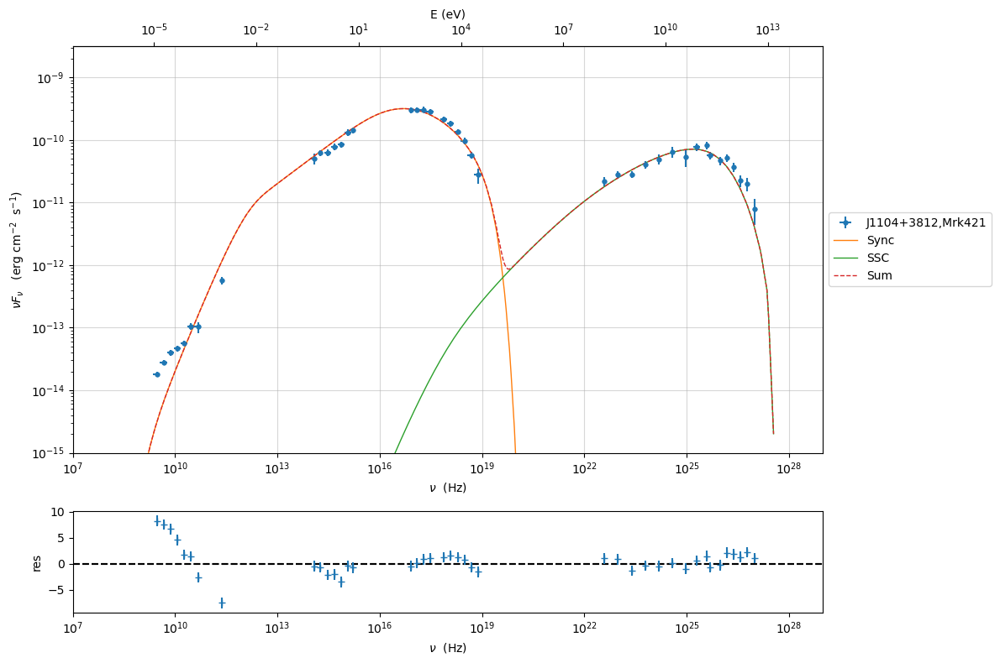

In [11]:
prefit_jet.eval()
pl=prefit_jet.plot_model(sed_data=sed_data)
pl.add_residual_plot(prefit_jet,sed_data)
pl.setlim(y_min=1E-15,x_min=1E7,x_max=1E29)

## Model fitting procedure

### Building the fit model

In [12]:
from jetset.minimizer import fit_SED,ModelMinimizer

from jetset.model_manager import  FitModel
from jetset.jet_model import Jet


In [13]:
from jetset.jet_radio_component import RadioSpectrum
radio_spectrum=RadioSpectrum()

if you want to fit the `prefit_model` you can load the saved one (this allows you to save time) ad pass it to the `FitModel` class

In [14]:
prefit_jet=Jet.load_model('prefit_jet.pkl')
fit_model=FitModel( jet=prefit_jet, name='SSC-best-fit-lsb',template=None) 


/Users/orion/miniforge3/envs/jetset/lib/python3.12/site-packages/jetset/model_manager.py:259: UserWarning: no cosmology defined, using the one from jet FlatLambdaCDM(name="Planck13", H0=67.77 km / (Mpc s), Om0=0.30712, Tcmb0=2.7255 K, Neff=3.046, m_nu=[0.   0.   0.06] eV, Ob0=0.048252)
  warnings.warn(m)


In [15]:
fit_model.add_component(radio_spectrum)

OR use the one generated above

In [16]:
fit_model.show_model_components()


--------------------------------------------------------------------------------
Composite model description
--------------------------------------------------------------------------------
name: SSC-best-fit-lsb  
type: composite_model  
components models:
 -model name: jet_leptonic model type: jet
 -model name: radio_spectrum model type: radio_spectrum

--------------------------------------------------------------------------------


There are now two components:  `jet_leptonic` and  `radio_spectrum`

We now set the gamma grid size to 200, ad we set `composite_expr`, anyhow, since we have only one component this step could be skipped

In [17]:
fit_model.jet_leptonic.set_gamma_grid_size(200)
fit_model.composite_expr='(jet_leptonic+radio_spectrum)'

In [18]:
fit_model.parameters

model name,name,par type,units,val,phys. bound. min,phys. bound. max,log,frozen
jet_leptonic,gmin,low-energy-cut-off,lorentz-factor*,4.697542e+02,1.000000e+00,1.000000e+09,False,False
jet_leptonic,gmax,high-energy-cut-off,lorentz-factor*,1.300733e+06,1.000000e+00,1.000000e+15,False,False
jet_leptonic,N,emitters_density,1 / cm3,6.642891e-01,0.000000e+00,--,False,False
jet_leptonic,gamma0_log_parab,turn-over-energy,lorentz-factor*,3.199366e+04,1.000000e+00,1.000000e+09,False,False
jet_leptonic,s,LE_spectral_slope,,2.177996e+00,-1.000000e+01,1.000000e+01,False,False
jet_leptonic,r,spectral_curvature,,7.629792e-01,-1.500000e+01,1.500000e+01,False,False
jet_leptonic,R,region_size,cm,3.403569e+16,1.000000e+03,1.000000e+30,False,False
jet_leptonic,R_H,region_position,cm,1.000000e+17,0.000000e+00,--,False,True
jet_leptonic,B,magnetic_field,gauss,5.050000e-02,0.000000e+00,--,False,False
jet_leptonic,NH_cold_to_rel_e,cold_p_to_rel_e_ratio,,1.000000e+00,0.000000e+00,--,False,True


None

#### Freezeing parameters and setting fit_range intervals

These methods are alternative and equivalent ways to access a model component for setting parameters state and values or freezing 


a) passing as first argument, of the method, the model component `name` and as second the `parameter name`


b) accessing the model component member of the composite model class, and accessing the `parameter` object member  

In [19]:
#a
fit_model.freeze('jet_leptonic','z_cosm')


#b
fit_model.jet_leptonic.parameters.R_H.frozen=True

fit_model.jet_leptonic.parameters.R.fit_range=[10**15.5,10**17.5]
fit_model.jet_leptonic.parameters.beam_obj.fit_range=[5., 50.]
fit_model.jet_leptonic.parameters.B.fit_range=[1E-3, 1]
fit_model.jet_leptonic.parameters.s.fit_range=[1, 3]
fit_model.jet_leptonic.parameters.r.fit_range=[.1, 2]
fit_model.jet_leptonic.parameters.gamma0_log_parab.fit_range=[1000, 1E6]
fit_model.jet_leptonic.parameters.gmin.fit_range=[2, 5E3]
fit_model.jet_leptonic.parameters.gmax.fit_range=[1E4, 1E7]


fit_model.radio_spectrum.parameters.nu_ssa.fit_range=[1E7, 5E10]
fit_model.radio_spectrum.parameters.alpha_radio.fit_range=[-1, 1]

fit_model.radio_spectrum.parameters.nuFnu_p.fit_range=[1E-14, 1E-12]



#### Building the  object

**Since the pre-fit model was very close to the data, we degrade the model in order to provide a more robust benchmark to the fitter, but this is not required!!!**

In [20]:
fit_model.jet_leptonic.parameters.N.val=1
fit_model.jet_leptonic.parameters.r.val=1.0
fit_model.jet_leptonic.parameters.beam_obj.val=20
fit_model.radio_spectrum.parameters.alpha_radio.val=0.1

fit_model.eval()

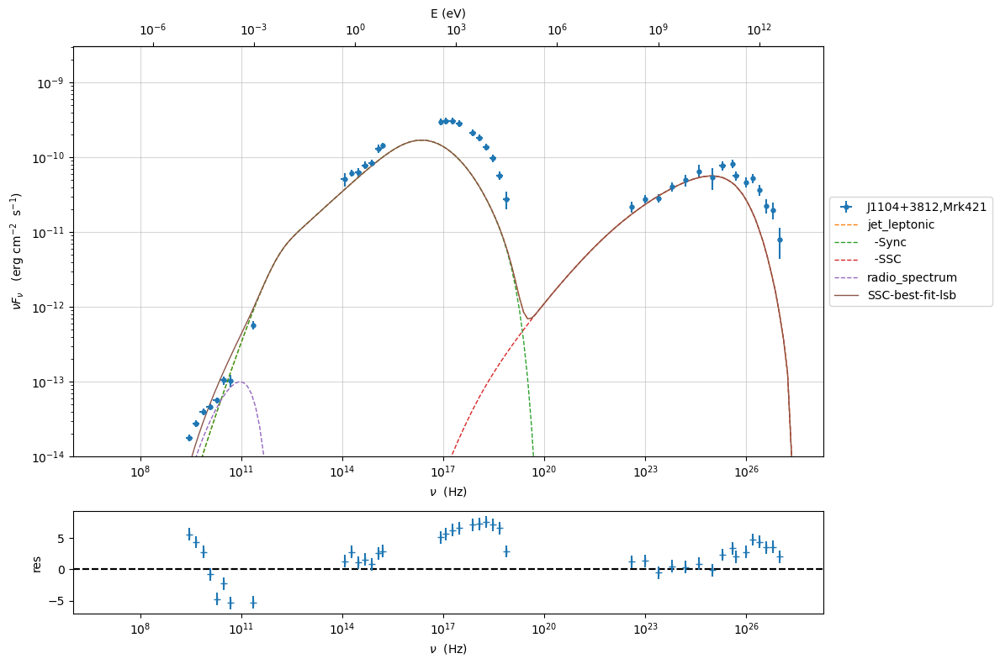

In [21]:
%matplotlib inline
fit_model.set_nu_grid(1E6,1E30,200)
fit_model.eval()
p2=fit_model.plot_model(sed_data=sed_data)
p2.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

## MCMC sampling

### creating and setting the sampler

In [22]:
from jetset.mcmc import McmcSampler
from jetset.minimizer import ModelMinimizer


We create a `ModelMinimizer` object directly for the MCMC step, skipping the `.run()` method, replaced by the call of the `prepare_fit` method.

In [23]:
model_minimizer = model_minimizer=ModelMinimizer('mcmc')
model_minimizer.prepare_fit(fit_model,
                            sed_data,
                            nu_fit_start=1E7,
                            nu_fit_stop=1E29,
                            use_UL=True)

mcmc=McmcSampler(model_minimizer)


filtering data in fit range = [1.000000e+07,1.000000e+29]
data length 41


You can inspect the mcmc parameters using:

In [24]:
mcmc.sampler_parameters

model name,name,val,log,bestfit mcmc,q16,q50,q84,mcmc bound min,mcmc bound max,frozen
str14,str16,float64,bool,float64,float64,float64,float64,float64,float64,bool
jet_leptonic,gmin,4.697542e+02,False,4.697542e+02,--,--,--,2.000000e+00,5.000000e+03,False
jet_leptonic,gmax,1.300733e+06,False,1.300733e+06,--,--,--,1.000000e+04,1.000000e+07,False
jet_leptonic,N,1.000000e+00,False,1.000000e+00,--,--,--,0.000000e+00,--,False
jet_leptonic,gamma0_log_parab,3.199366e+04,False,3.199366e+04,--,--,--,1.000000e+03,1.000000e+06,False
jet_leptonic,s,2.177996e+00,False,2.177996e+00,--,--,--,1.000000e+00,3.000000e+00,False
jet_leptonic,r,1.000000e+00,False,1.000000e+00,--,--,--,1.000000e-01,2.000000e+00,False
jet_leptonic,R,3.403569e+16,False,3.403569e+16,--,--,--,3.162278e+15,3.162278e+17,False
jet_leptonic,B,5.050000e-02,False,5.050000e-02,--,--,--,1.000000e-03,1.000000e+00,False
jet_leptonic,beam_obj,2.000000e+01,False,2.000000e+01,--,--,--,5.000000e+00,5.000000e+01,False


If you want to exclude or include parameters from the samplers just freeze/free them 

In [25]:
mcmc.model.radio_spectrum.parameters.nu_ssa.frozen=True


You can set different bounds for all the free parameters with the instruction below. In case you want to preserve the `fit_range` defined in the frequentist minimizer you can pass `preserve_fit_range=True`

In [26]:
mcmc.set_bounds(bound=5.0,bound_rel=True)

par: gmin  ref value:  469.75417594471753  mcmc bounds: [2, np.float64(2818.5250556683054)]
par: gmax  ref value:  1300732.557299546  mcmc bounds: [10000.0, np.float64(7804395.343797276)]
par: N  ref value:  1  mcmc bounds: [0, np.float64(6.0)]
par: gamma0_log_parab  ref value:  31993.66108749595  mcmc bounds: [1000, np.float64(191961.9665249757)]
par: s  ref value:  2.1779959351515963  mcmc bounds: [1, 3]
par: r  ref value:  1.0  mcmc bounds: [0.1, 2]
par: R  ref value:  3.403569316682212e+16  mcmc bounds: [3162277660168379.5, np.float64(2.042141590009327e+17)]
par: B  ref value:  0.0505  mcmc bounds: [0.001, np.float64(0.303)]
par: beam_obj  ref value:  20  mcmc bounds: [5.0, 50.0]
par: alpha_radio  ref value:  0.1  mcmc bounds: [np.float64(-0.4), np.float64(0.6)]
par: nu_cut  ref value:  100000000000.0  mcmc bounds: [1000000.0, np.float64(600000000000.0)]
par: nuFnu_p  ref value:  1e-13  mcmc bounds: [1e-14, np.float64(6e-13)]


Or, you can set per-parameter bounds as follows, passing the actual bound for each parameter.

In [27]:
mcmc.set_bounds(comp_name='jet_leptonic',par_name='N',par_bounds=[1E-5,10])
mcmc.set_bounds(comp_name='radio_spectrum',par_name='alpha_radio',par_bounds=[0,1])
mcmc.set_bounds(comp_name='radio_spectrum',par_name='nuFnu_p',par_bounds=[3E-14,3E-13])
mcmc.set_bounds(comp_name='radio_spectrum',par_name='nu_cut',par_bounds=[3E10,3E11])

par: N  ref value:  1  mcmc bounds: [1e-05, 10]
par: alpha_radio  ref value:  0.1  mcmc bounds: [0, 1]
par: nuFnu_p  ref value:  1e-13  mcmc bounds: [3e-14, 3e-13]
par: nu_cut  ref value:  100000000000.0  mcmc bounds: [30000000000.0, 300000000000.0]


In [28]:
mcmc.sampler_parameters

model name,name,val,log,bestfit mcmc,q16,q50,q84,mcmc bound min,mcmc bound max,frozen
str14,str16,float64,bool,float64,float64,float64,float64,float64,float64,bool
jet_leptonic,gmin,4.697542e+02,False,4.697542e+02,--,--,--,2.000000e+00,2.818525e+03,False
jet_leptonic,gmax,1.300733e+06,False,1.300733e+06,--,--,--,1.000000e+04,7.804395e+06,False
jet_leptonic,N,1.000000e+00,False,1.000000e+00,--,--,--,1.000000e-05,1.000000e+01,False
jet_leptonic,gamma0_log_parab,3.199366e+04,False,3.199366e+04,--,--,--,1.000000e+03,1.919620e+05,False
jet_leptonic,s,2.177996e+00,False,2.177996e+00,--,--,--,1.000000e+00,3.000000e+00,False
jet_leptonic,r,1.000000e+00,False,1.000000e+00,--,--,--,1.000000e-01,2.000000e+00,False
jet_leptonic,R,3.403569e+16,False,3.403569e+16,--,--,--,3.162278e+15,2.042142e+17,False
jet_leptonic,B,5.050000e-02,False,5.050000e-02,--,--,--,1.000000e-03,3.030000e-01,False
jet_leptonic,beam_obj,2.000000e+01,False,2.000000e+01,--,--,--,5.000000e+00,5.000000e+01,False


Since we are not starting from a minimized model, we need to check for the convergence. Let's increase the `burnin` size and the number of `steps`. Once the fit is done, we check the chains, and we tune the `burnin` by using the `tune_burnin` method.

In [29]:
mcmc.run_sampler(nwalkers=30, burnin=100,steps=2000,progress='notebook')


mcmc run starting



  0%|          | 0/2000 [00:00<?, ?it/s]

mcmc run done, with 1 threads took 71.94 seconds
----------------------------
MCMC best fit solution
comp: jet_leptonic par: gmin  mcmc best fit val: 861.2865481425015 quantiles(0.16,0.5,0.84): [ 742.3618648   862.46174231 1002.32331004] 
comp: jet_leptonic par: gmax  mcmc best fit val: 2946959.2433712697 quantiles(0.16,0.5,0.84): [1016215.75651336 1700537.94324399 3848792.66471946] 
comp: jet_leptonic par: N  mcmc best fit val: 0.7566640523471369 quantiles(0.16,0.5,0.84): [0.34129007 0.50088597 0.73277135] 
comp: jet_leptonic par: gamma0_log_parab  mcmc best fit val: 115018.66988070788 quantiles(0.16,0.5,0.84): [33050.66051343 51381.80749137 99313.04108946] 
comp: jet_leptonic par: s  mcmc best fit val: 2.3652285399829864 quantiles(0.16,0.5,0.84): [2.15666368 2.25417189 2.34184268] 
comp: jet_leptonic par: r  mcmc best fit val: 1.6955501793019998 quantiles(0.16,0.5,0.84): [0.68821976 0.95979216 1.56305838] 
comp: jet_leptonic par: R  mcmc best fit val: 2.3355928447517052e+16 quantiles

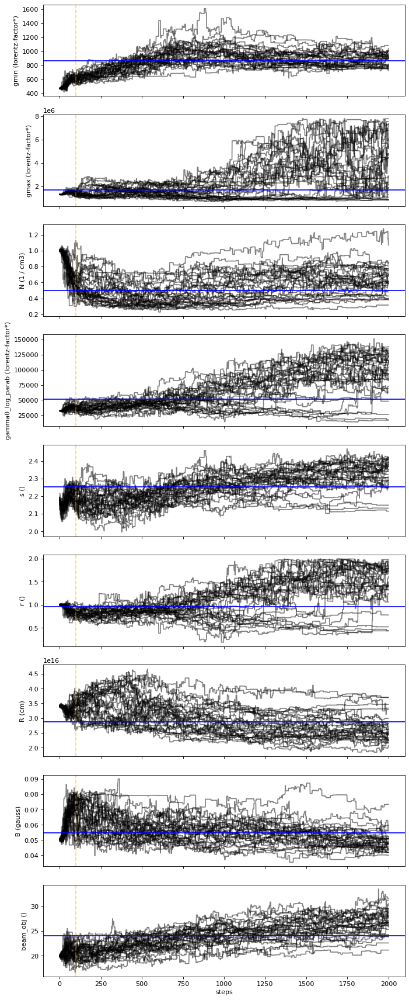

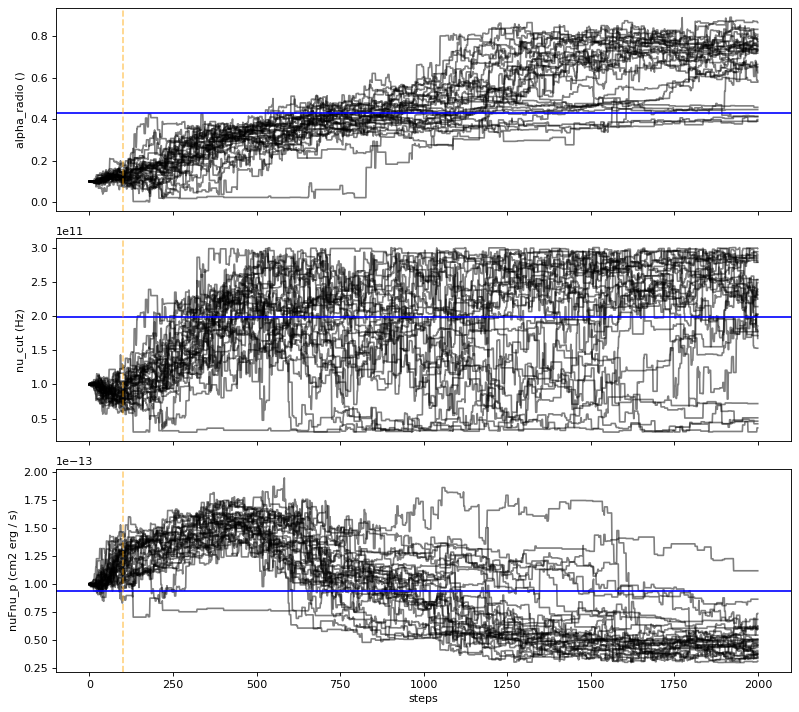

In [30]:
import matplotlib as mpl

mpl.rcParams['figure.dpi'] = 80
f=mcmc.plot_chain(log_plot=False)
plt.tight_layout()

In [31]:
mcmc.tune_burnin()

----------------------------
MCMC best fit solution
comp: jet_leptonic par: gmin  mcmc best fit val: 861.2865481425015 quantiles(0.16,0.5,0.84): [ 772.46086196  880.58666502 1012.09451982] 
comp: jet_leptonic par: gmax  mcmc best fit val: 2946959.2433712697 quantiles(0.16,0.5,0.84): [ 998782.07416935 1799350.26641169 4123313.83830238] 
comp: jet_leptonic par: N  mcmc best fit val: 0.7566640523471369 quantiles(0.16,0.5,0.84): [0.33873908 0.50418621 0.73294183] 
comp: jet_leptonic par: gamma0_log_parab  mcmc best fit val: 115018.66988070788 quantiles(0.16,0.5,0.84): [ 33905.82601707  56227.17776601 102568.05029553] 
comp: jet_leptonic par: s  mcmc best fit val: 2.3652285399829864 quantiles(0.16,0.5,0.84): [2.16762677 2.26200225 2.34517164] 
comp: jet_leptonic par: r  mcmc best fit val: 1.6955501793019998 quantiles(0.16,0.5,0.84): [0.67924135 1.02785627 1.59252052] 
comp: jet_leptonic par: R  mcmc best fit val: 2.3355928447517052e+16 quantiles(0.16,0.5,0.84): [2.37182512e+16 2.81730004e+1

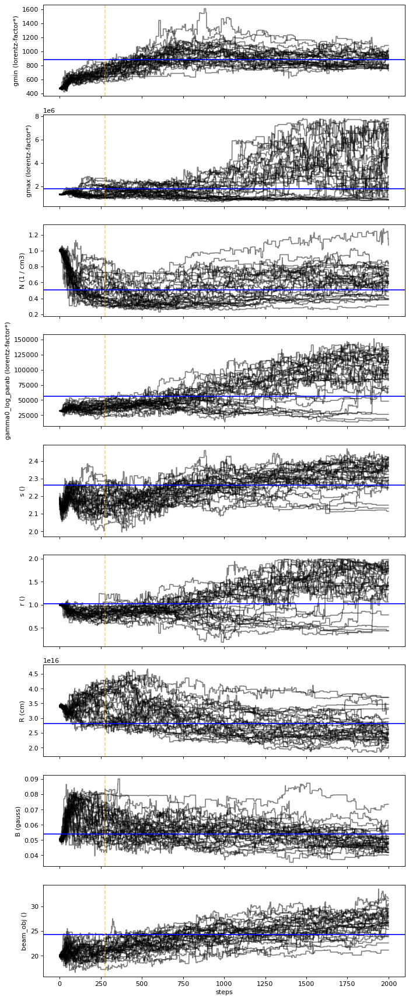

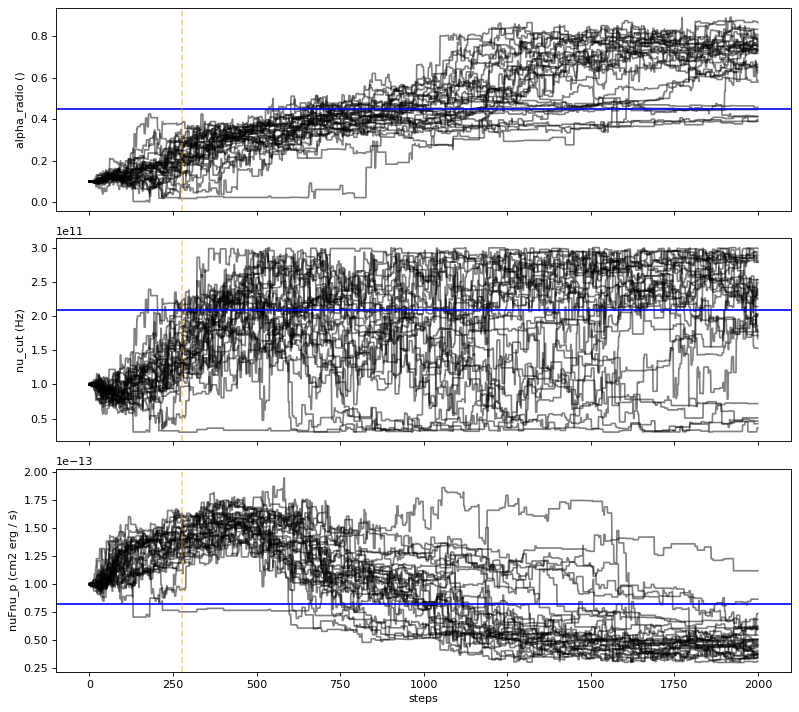

In [32]:
mpl.rcParams['figure.dpi'] = 80
f=mcmc.plot_chain(log_plot=False)
plt.tight_layout()

Showing the MCMC parameters. Now MCMC bestfit values are updated to the best-fit MCMC solution


In [33]:
mcmc.sampler_parameters

model name,name,val,log,bestfit mcmc,q16,q50,q84,mcmc bound min,mcmc bound max,frozen
str14,str16,float64,bool,float64,float64,float64,float64,float64,float64,bool
jet_leptonic,gmin,8.612865e+02,False,8.612865e+02,7.724609e+02,8.805867e+02,1.012095e+03,2.000000e+00,2.818525e+03,False
jet_leptonic,gmax,2.946959e+06,False,2.946959e+06,9.987821e+05,1.799350e+06,4.123314e+06,1.000000e+04,7.804395e+06,False
jet_leptonic,N,7.566641e-01,False,7.566641e-01,3.387391e-01,5.041862e-01,7.329418e-01,1.000000e-05,1.000000e+01,False
jet_leptonic,gamma0_log_parab,1.150187e+05,False,1.150187e+05,3.390583e+04,5.622718e+04,1.025681e+05,1.000000e+03,1.919620e+05,False
jet_leptonic,s,2.365229e+00,False,2.365229e+00,2.167627e+00,2.262002e+00,2.345172e+00,1.000000e+00,3.000000e+00,False
jet_leptonic,r,1.695550e+00,False,1.695550e+00,6.792413e-01,1.027856e+00,1.592521e+00,1.000000e-01,2.000000e+00,False
jet_leptonic,R,2.335593e+16,False,2.335593e+16,2.371825e+16,2.817300e+16,3.486605e+16,3.162278e+15,2.042142e+17,False
jet_leptonic,B,4.867381e-02,False,4.867381e-02,4.630482e-02,5.387670e-02,6.212469e-02,1.000000e-03,3.030000e-01,False
jet_leptonic,beam_obj,2.859667e+01,False,2.859667e+01,2.176147e+01,2.433428e+01,2.700497e+01,5.000000e+00,5.000000e+01,False


### plotting the posterior corner plot

To have a better rendering on the scatter plot, we redefine the plot labels

In [34]:
mcmc.set_plot_label('N',r'$N$',comp_name='jet_leptonic')
mcmc.set_plot_label('B',r'$B$',comp_name='jet_leptonic')
mcmc.set_plot_label('gmin',r'$\gamma_{\rm min}$',comp_name='jet_leptonic')
mcmc.set_plot_label('gmax',r'$\gamma_{\rm max}$',comp_name='jet_leptonic')
mcmc.set_plot_label('beam_obj',r'$\delta$',comp_name='jet_leptonic')
mcmc.set_plot_label('s',r'$s$',comp_name='jet_leptonic')
mcmc.set_plot_label('r',r'$r$',comp_name='jet_leptonic')
mcmc.set_plot_label('gamma0_log_parab',r'$\gamma_0$',comp_name='jet_leptonic')
mcmc.set_plot_label('alpha_radio',r'$\alpha_{\rm Radio}$',comp_name='radio_spectrum')
mcmc.set_plot_label('nu_cut',r'$\nu_{\rm cut}$',comp_name='radio_spectrum')
mcmc.set_plot_label('nuFnu_p',r'$\nu F_{\nu}^{p}$',comp_name='radio_spectrum')

the code below lets you tuning the output

1) mpl.rcParams['figure.dpi'] if you increase it you get a better definition
2) title_fmt=".2E" this is the format for python, 2 significant digits, scientific notation
3) title_kwargs=dict(fontsize=12) you can change the fontsize

Per-component corner plot

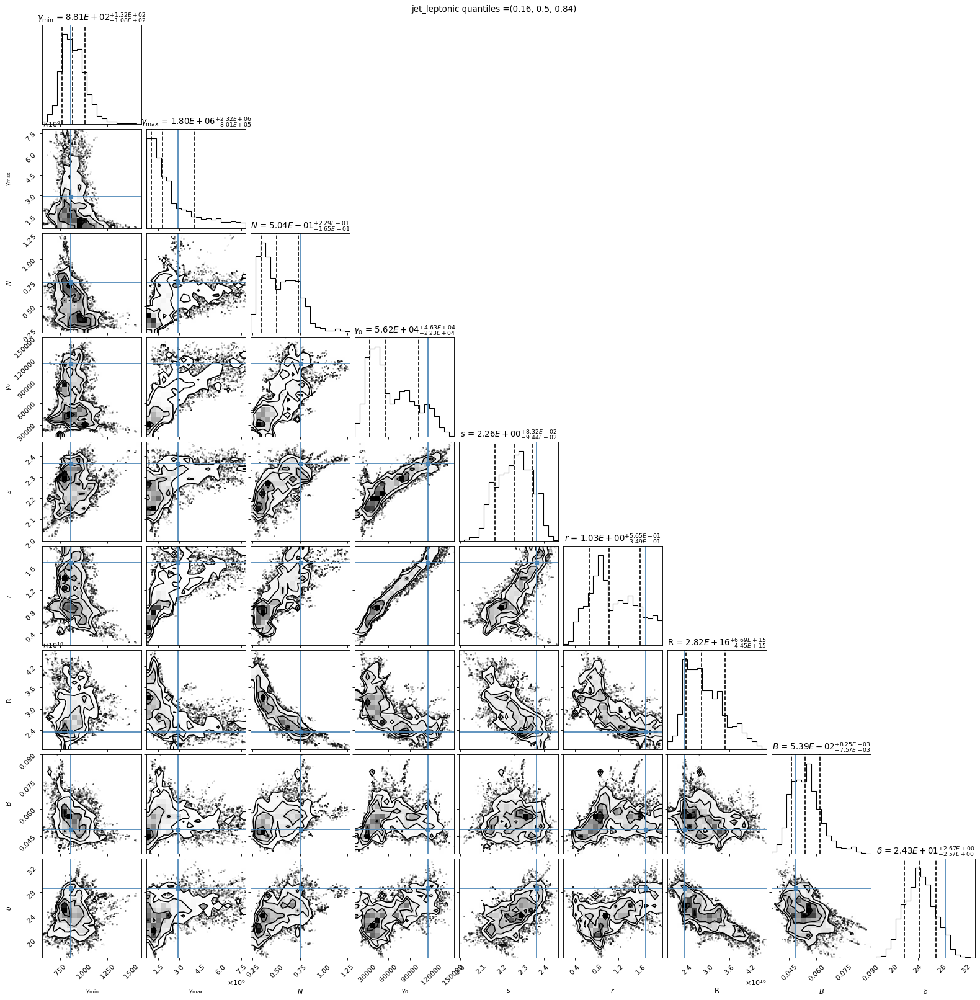

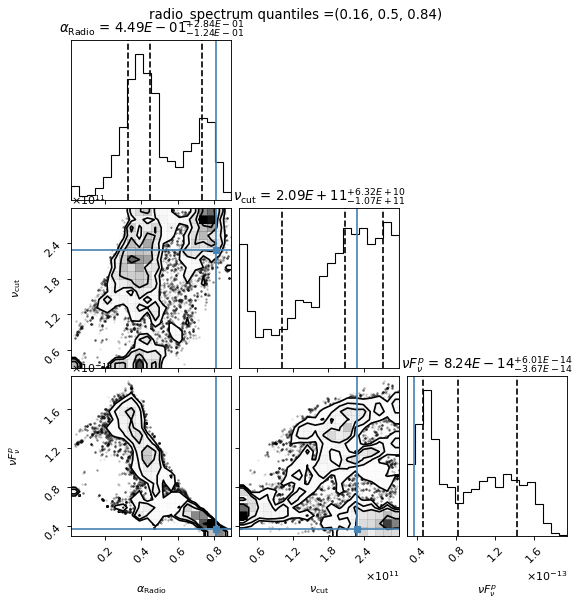

In [35]:

mpl.rcParams['figure.dpi'] = 80
f=mcmc.corner_plot(quantiles=(0.16, 0.5, 0.84),title_kwargs=dict(fontsize=12),title_fmt=".2E",use_math_text=True)

Global corner plot, pass `per_component=False`


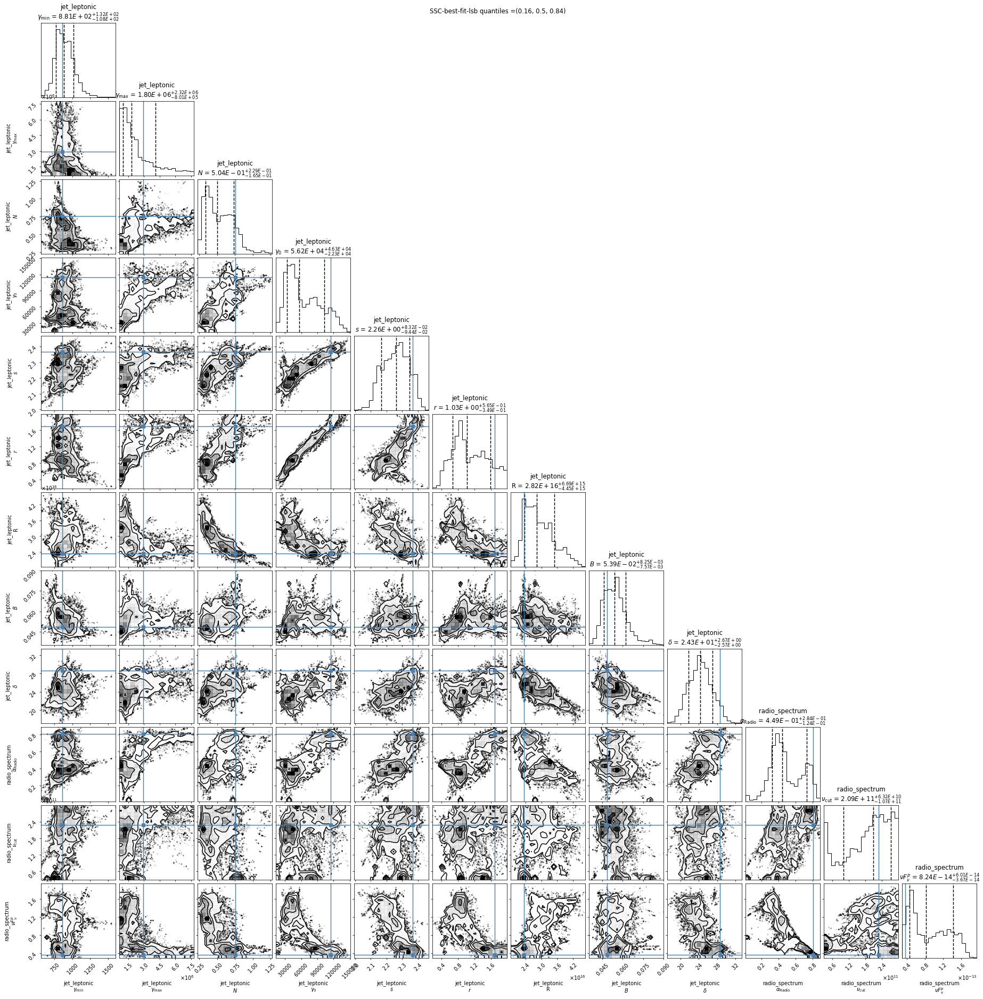

In [36]:
mpl.rcParams['figure.dpi'] = 70
f=mcmc.corner_plot(quantiles=(0.16, 0.5, 0.84),title_kwargs=dict(fontsize=12),title_fmt=".2E",use_math_text=True,per_component=False)

In [37]:
print(mcmc.acceptance_fraction)

0.18750000000000003


### plotting the model

To plot the sampled model range against the input mcmc best-fit model

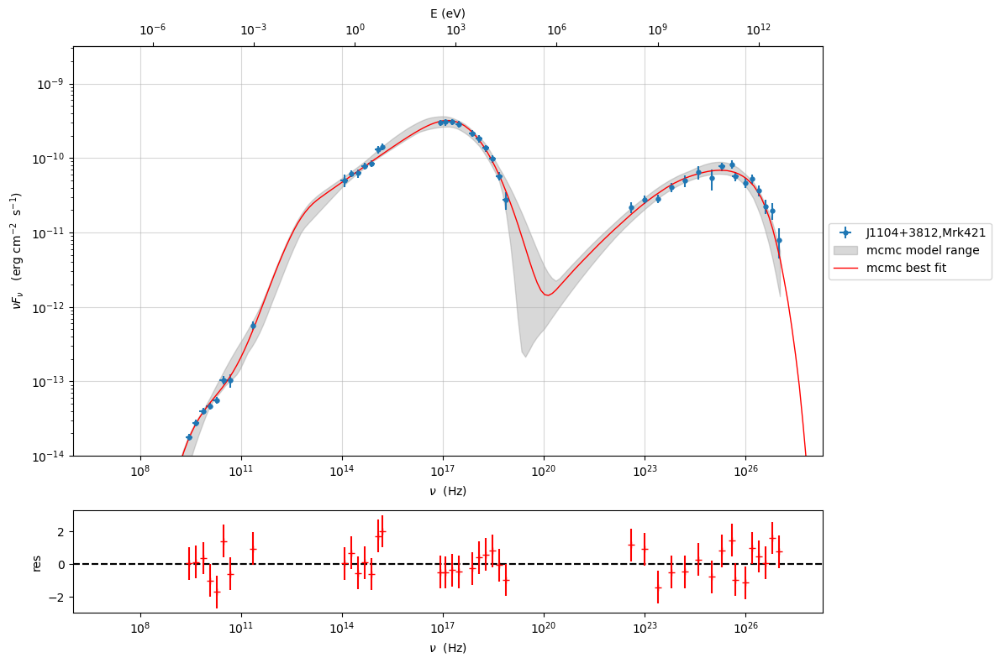

In [38]:

from jetset.data_loader import ObsData
sed_data=ObsData.load('Mrk_401.pkl')
mpl.rcParams['figure.dpi'] = 80
p=mcmc.plot_model(sed_data=sed_data,size=100)
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

To plot the mcmc best-fit model providing quantiles. The size parameter defines the number of samples to use to extract the quantiles. I am using a size equal to the number of steps

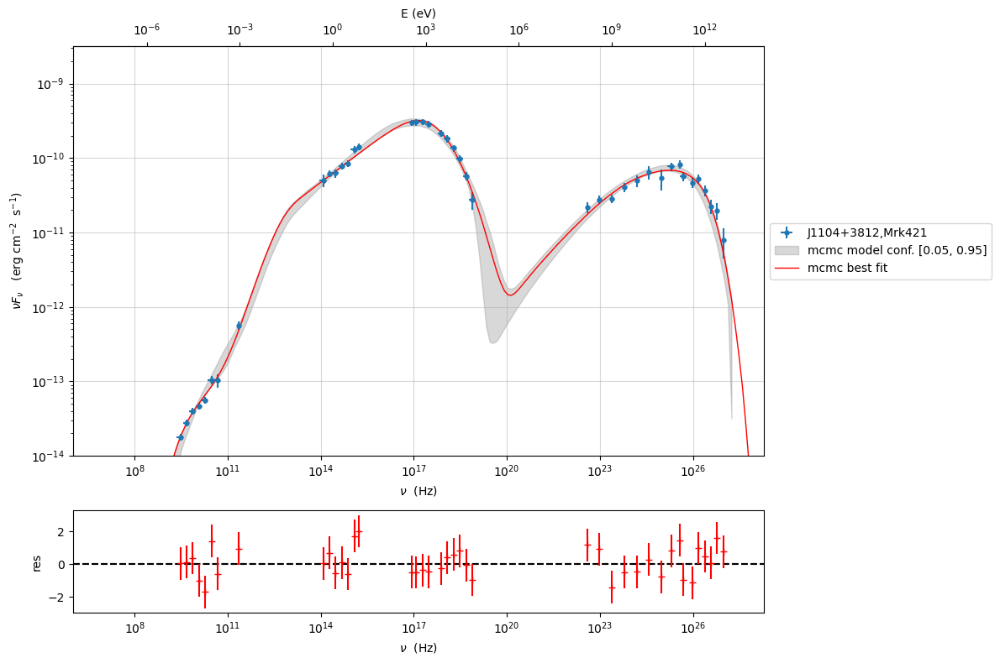

In [39]:
mpl.rcParams['figure.dpi'] = 80
p=mcmc.plot_model(sed_data=sed_data,size=100,quantiles=[0.05,0.95])
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

If you want to plot also the model components, pass the argument `plot_components=True`

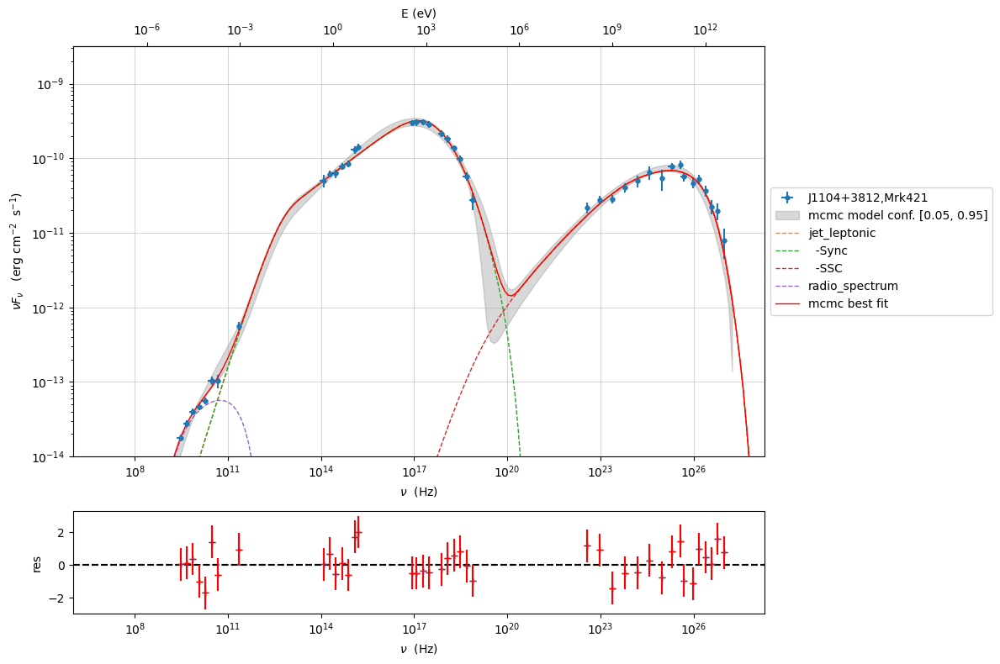

In [40]:
mpl.rcParams['figure.dpi'] = 80
p=mcmc.plot_model(sed_data=sed_data,size=500,quantiles=[0.05,0.95],plot_components=True)
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

To plot the frequentist  best-fit  model range,p roviding quantiles, provide (``plot_mcmc_best_fit_model==False``)

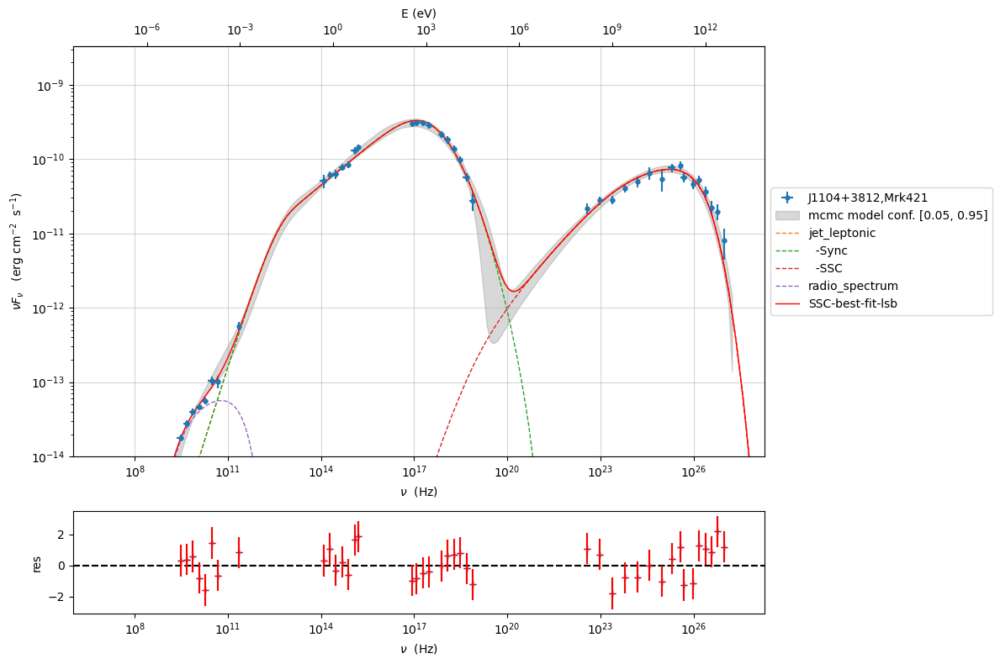

In [41]:
mpl.rcParams['figure.dpi'] = 100
p=mcmc.plot_model(sed_data=sed_data,size=500,quantiles=[0.05,0.95], plot_mcmc_best_fit_model=False,plot_components=True)
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

### plotting chains and individual posteriors

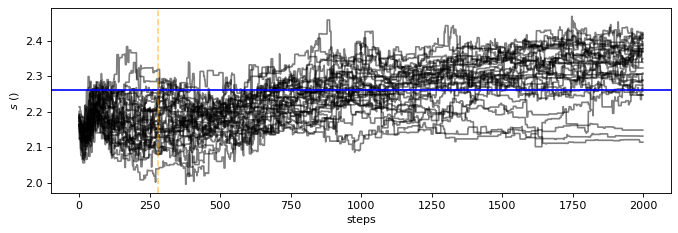

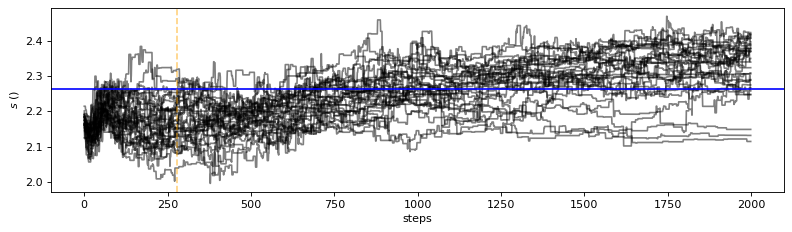

In [42]:
import matplotlib.pylab as plt

mpl.rcParams['figure.dpi'] = 80
f=mcmc.plot_chain(par_name='s',log_plot=False)
plt.tight_layout()

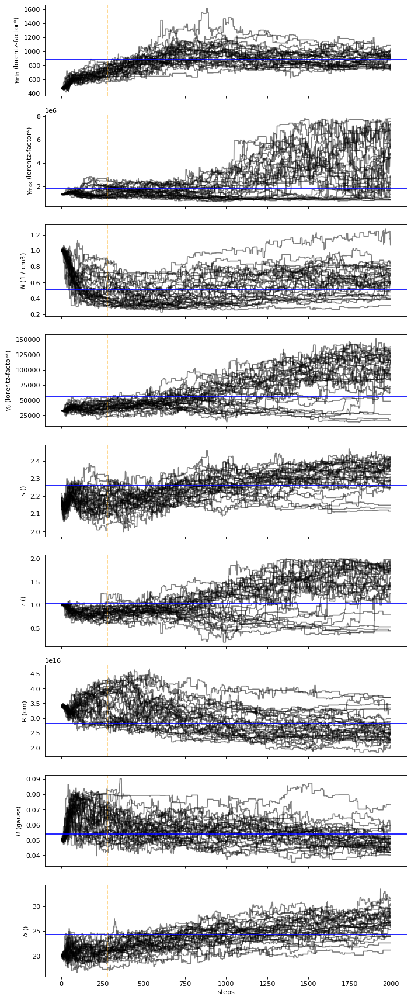

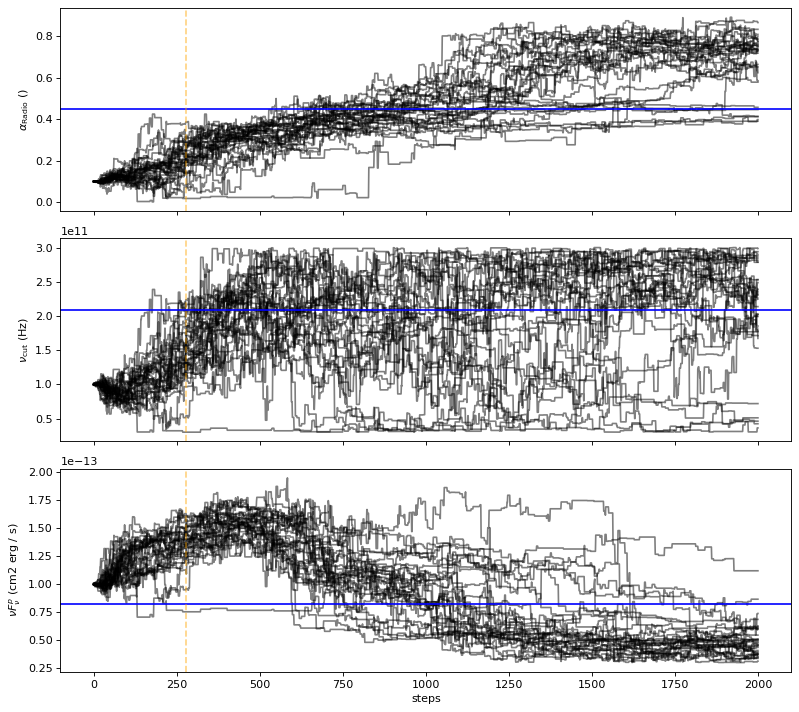

In [43]:
mpl.rcParams['figure.dpi'] = 80
f=mcmc.plot_chain(log_plot=False)
plt.tight_layout()

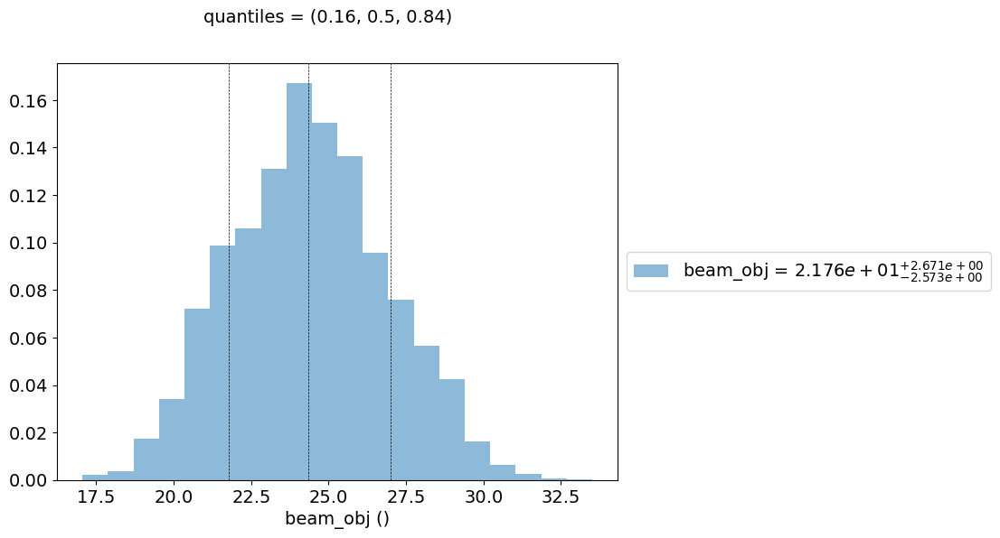

In [44]:

f=mcmc.plot_par('beam_obj',figsize=(8,6))
mpl.rcParams['figure.dpi'] = 80

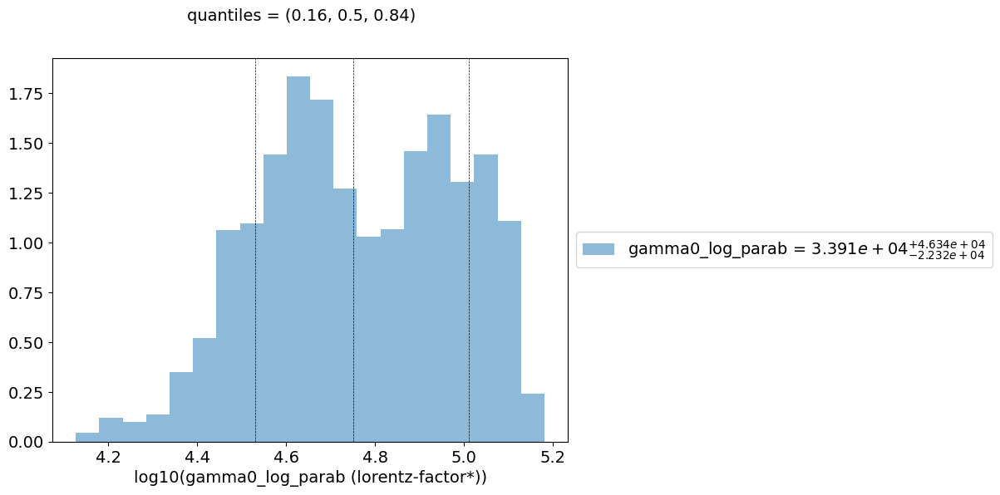

In [45]:
mpl.rcParams['figure.dpi'] = 80
f=mcmc.plot_par('gamma0_log_parab',log_plot=True,figsize=(8,6))

## Save and reuse MCMC

In [46]:
mcmc.save('mcmc_sampler.pkl')

In [47]:
from jetset.mcmc import McmcSampler
from jetset.data_loader import ObsData

sed_data=ObsData.load('Mrk_401.pkl')
ms=McmcSampler.load('mcmc_sampler.pkl')

import matplotlib as mpl


In [48]:
ms.sampler_parameters

model name,name,val,log,bestfit mcmc,q16,q50,q84,mcmc bound min,mcmc bound max,frozen
str14,str16,float64,bool,float64,float64,float64,float64,float64,float64,bool
jet_leptonic,gmin,8.612865e+02,False,8.612865e+02,7.724609e+02,8.805867e+02,1.012095e+03,2.000000e+00,2.818525e+03,False
jet_leptonic,gmax,2.946959e+06,False,2.946959e+06,9.987821e+05,1.799350e+06,4.123314e+06,1.000000e+04,7.804395e+06,False
jet_leptonic,N,7.566641e-01,False,7.566641e-01,3.387391e-01,5.041862e-01,7.329418e-01,1.000000e-05,1.000000e+01,False
jet_leptonic,gamma0_log_parab,1.150187e+05,False,1.150187e+05,3.390583e+04,5.622718e+04,1.025681e+05,1.000000e+03,1.919620e+05,False
jet_leptonic,s,2.365229e+00,False,2.365229e+00,2.167627e+00,2.262002e+00,2.345172e+00,1.000000e+00,3.000000e+00,False
jet_leptonic,r,1.695550e+00,False,1.695550e+00,6.792413e-01,1.027856e+00,1.592521e+00,1.000000e-01,2.000000e+00,False
jet_leptonic,R,2.335593e+16,False,2.335593e+16,2.371825e+16,2.817300e+16,3.486605e+16,3.162278e+15,2.042142e+17,False
jet_leptonic,B,4.867381e-02,False,4.867381e-02,4.630482e-02,5.387670e-02,6.212469e-02,1.000000e-03,3.030000e-01,False
jet_leptonic,beam_obj,2.859667e+01,False,2.859667e+01,2.176147e+01,2.433428e+01,2.700497e+01,5.000000e+00,5.000000e+01,False


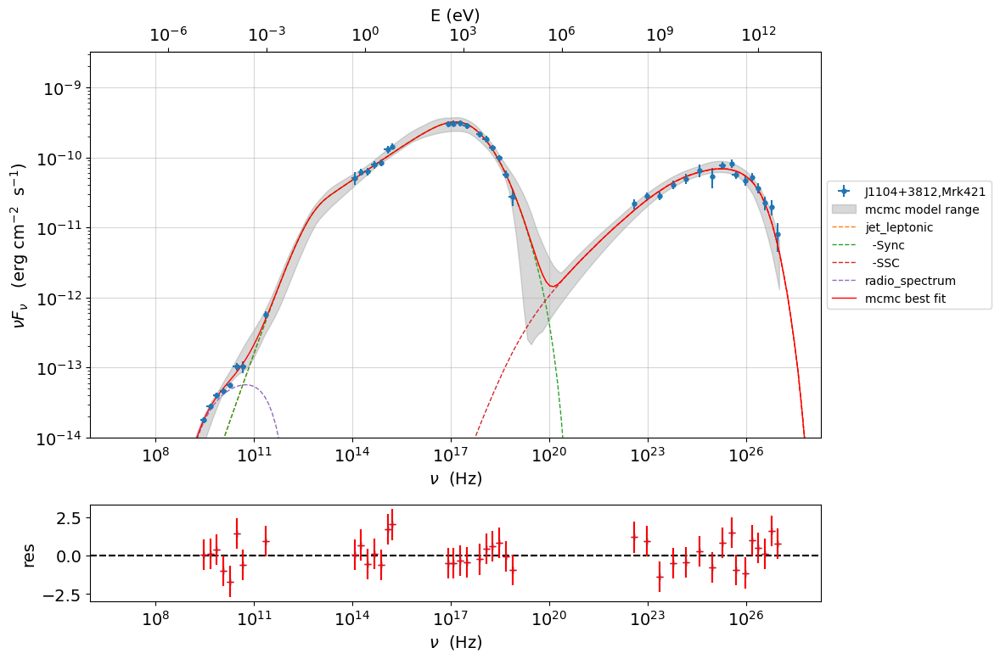

In [49]:
mpl.rcParams['figure.dpi'] = 80
p=ms.plot_model(sed_data=sed_data,size=500,plot_components=True)
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

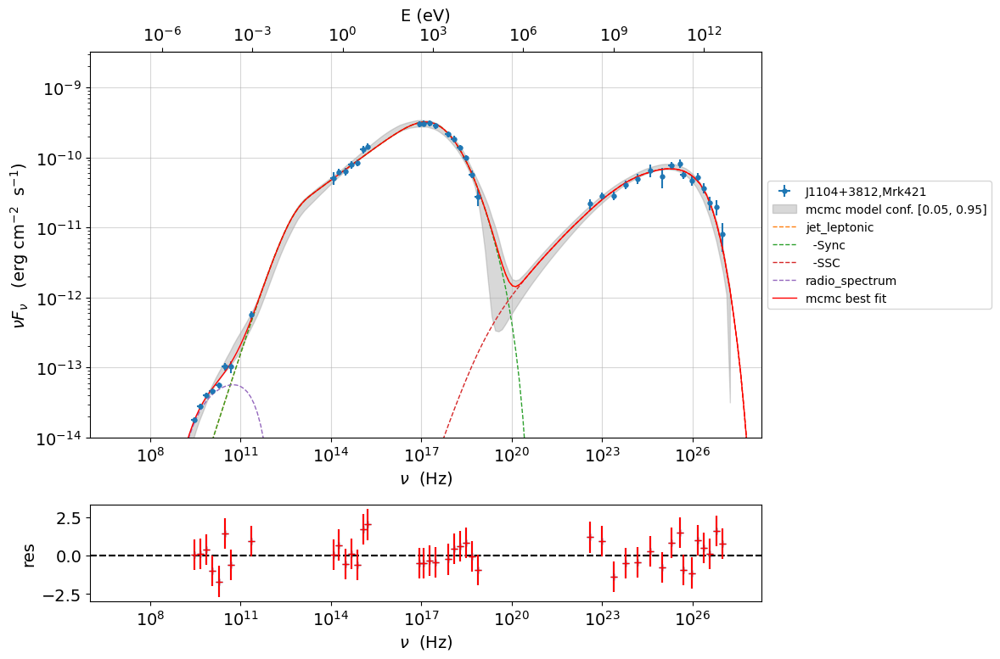

In [50]:
mpl.rcParams['figure.dpi'] = 80
p=ms.plot_model(sed_data=sed_data,size=100,quantiles=[0.05,0.95],plot_components=True)
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

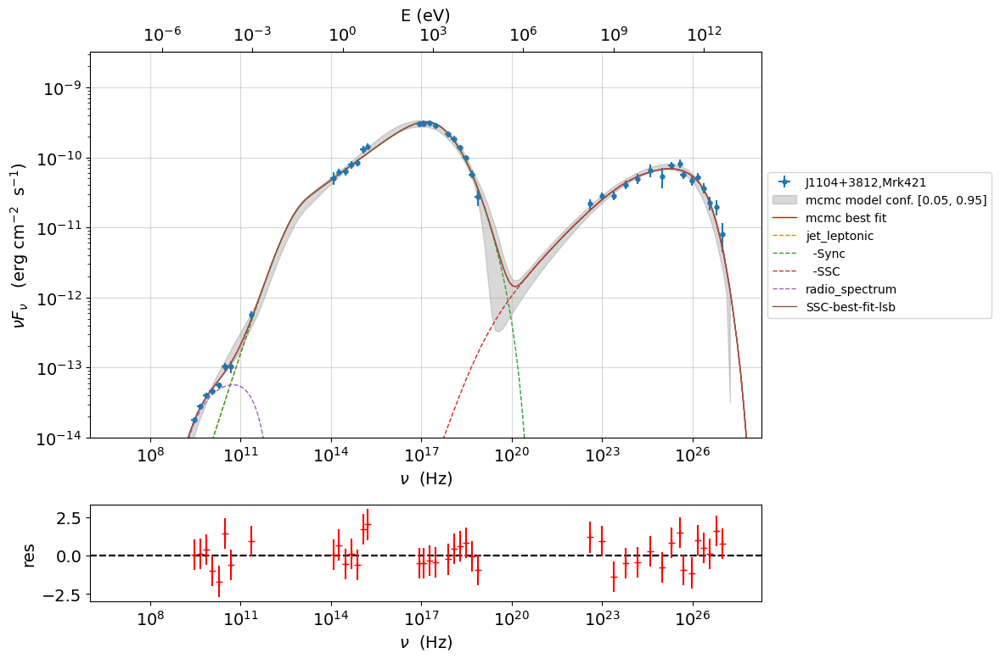

In [51]:
mpl.rcParams['figure.dpi'] = 80
p=ms.plot_model(sed_data=sed_data,size=100,quantiles=[0.05,0.95],plot_mcmc_best_fit_model=True)
p=ms.model.plot_model(plot_obj=p)
p.setlim(y_min=1E-14,x_min=1E6,x_max=2E28)

Per-component corner plot

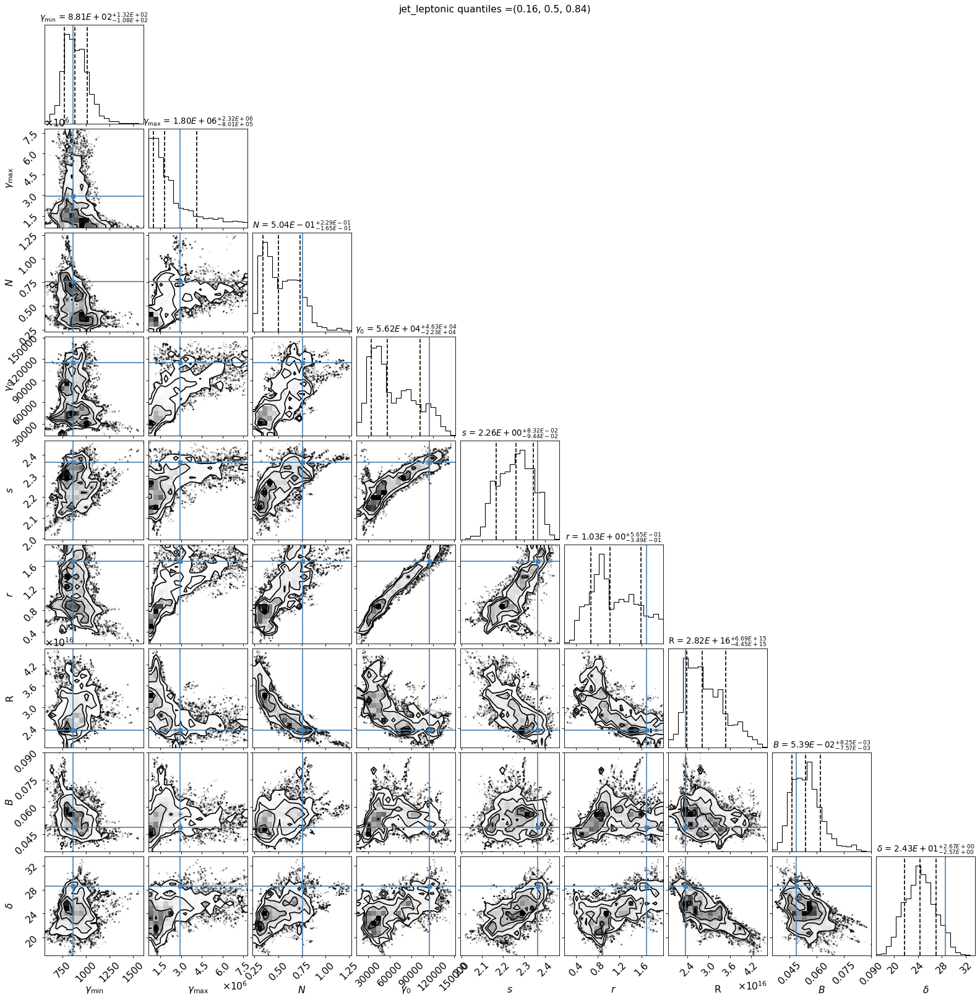

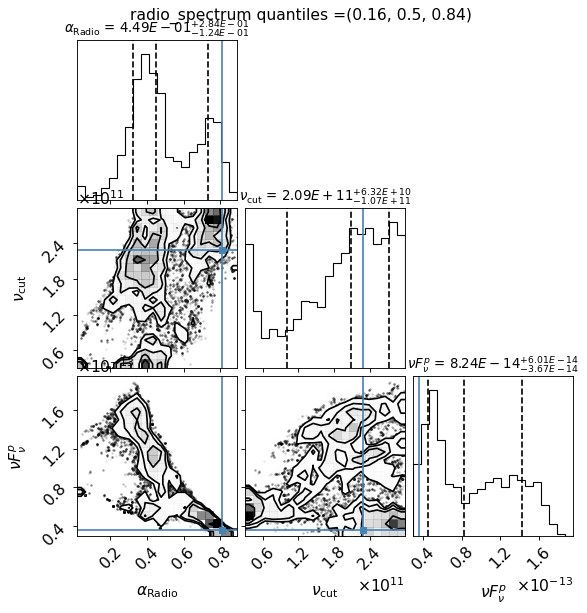

In [52]:
mpl.rcParams['figure.dpi'] = 80
f=ms.corner_plot(quantiles=(0.16, 0.5, 0.84),title_kwargs=dict(fontsize=12),title_fmt=".2E",use_math_text=True)

Global corner plot, pass `per_component=False`


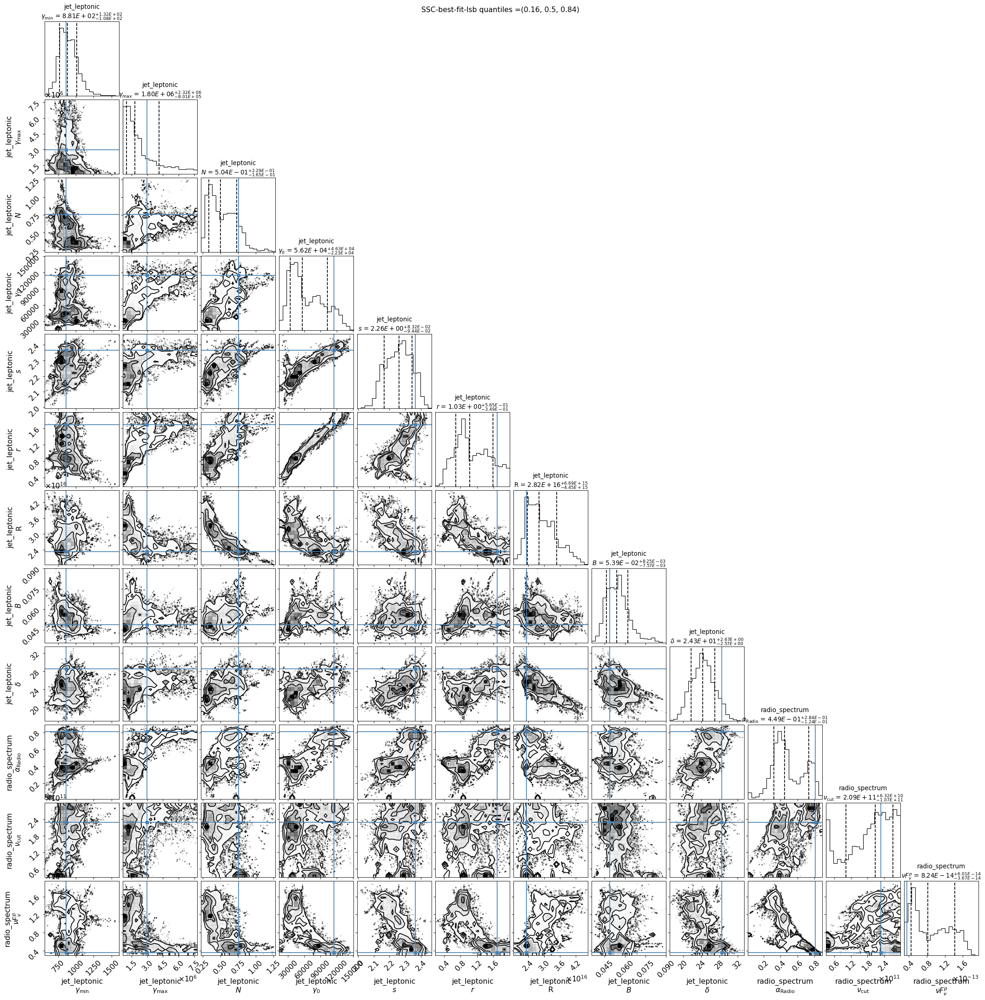

In [53]:
mpl.rcParams['figure.dpi'] = 80
f=ms.corner_plot(quantiles=(0.16, 0.5, 0.84),title_kwargs=dict(fontsize=12),title_fmt=".2E",use_math_text=True,per_component=False)

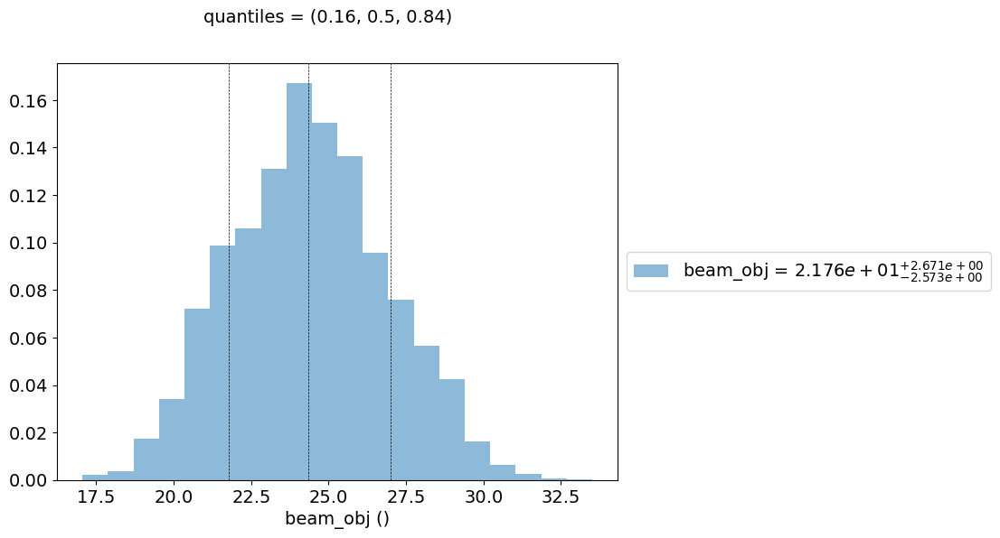

In [54]:
mpl.rcParams['figure.dpi'] = 80
f=ms.plot_par('beam_obj',log_plot=False,figsize=(8,6))

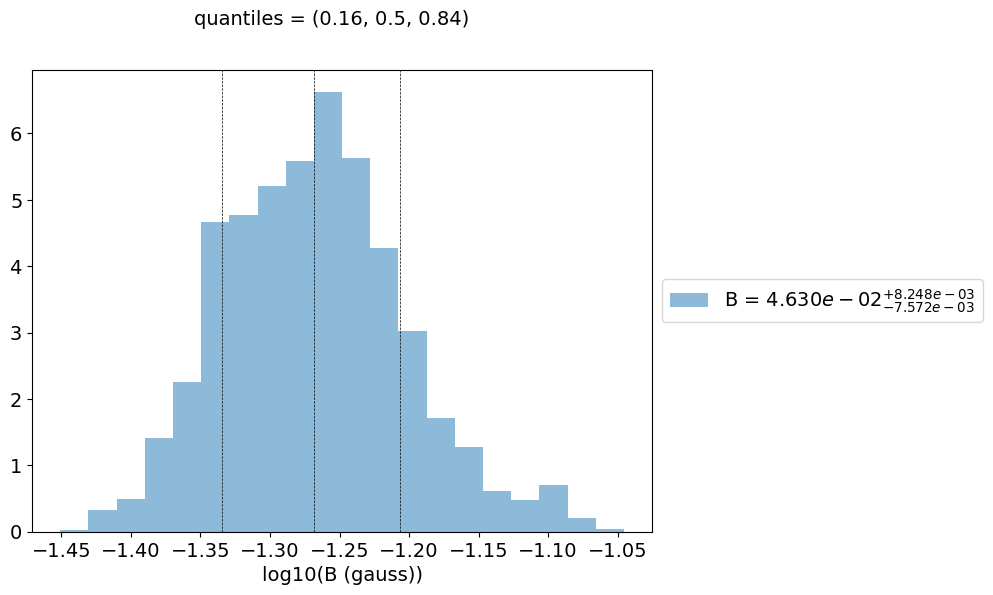

In [55]:
f=ms.plot_par('B',log_plot=True,figsize=(8,6))

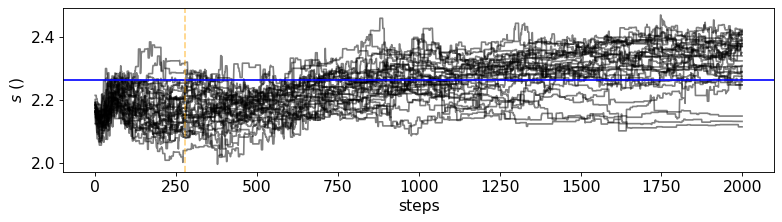

In [56]:
from matplotlib import pylab as plt
mpl.rcParams['figure.dpi'] = 80
f=ms.plot_chain(par_name='s',comp_name='jet_leptonic',log_plot=False)
plt.tight_layout()

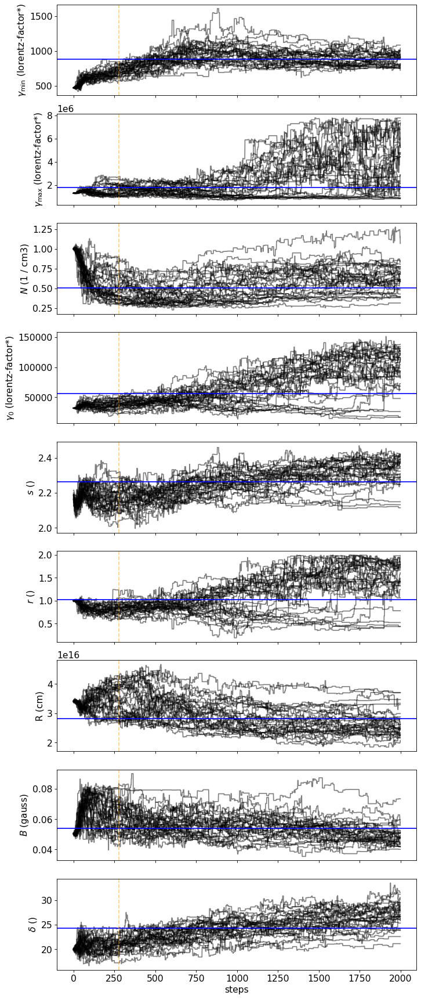

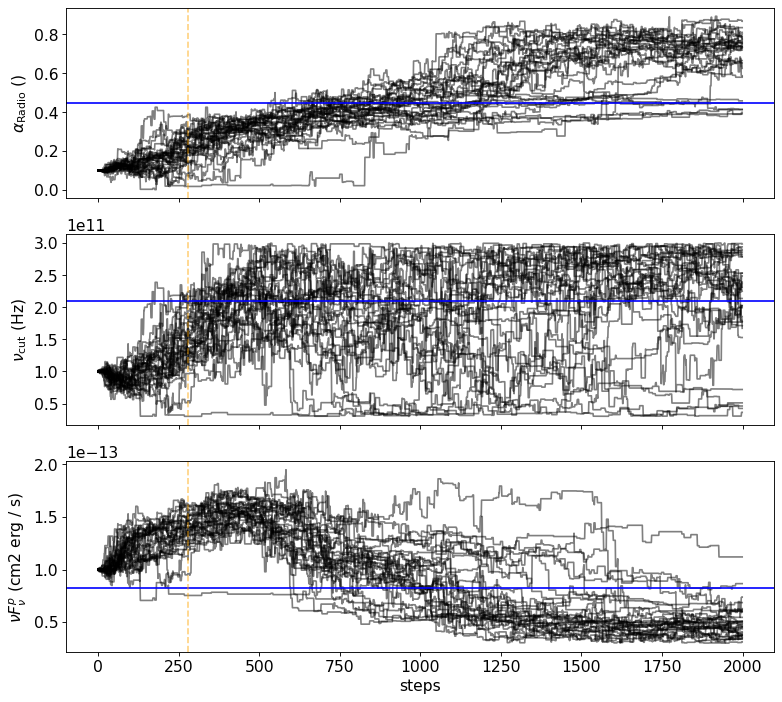

In [57]:
f=ms.plot_chain(log_plot=False)
plt.tight_layout()
mpl.rcParams['figure.dpi'] = 80